# Projet Data Mining : Détection d'Intrusions Réseau (NIDS)
## Notebook 01 : Exploration Approfondie des Données (EDA) & Nettoyage d'Intégrité

---
### Informations Générales
- **Auteurs :** GHOUL Sami & BELGHACHE Walid
- **Formation :** 4ᵉ année d'ingéniorat, Génie Logiciel — Université de Béjaïa
- **Module :** Data Mining & Apprentissage Automatique
- **Jeu de données :** UNSW-NB15 (`UNSW_NB15_training-set.parquet`)
- **Objectif du Notebook :** Explorer la structure du jeu de données réseau, analyser la distribution des classes normales et des attaques, évaluer la qualité des données (valeurs manquantes, infinies, doublons), supprimer les sources de fuite d'information (*Data Leakage*) et produire le dataset d'entraînement nettoyé.
---

## 1. Importation des Bibliothèques & Configuration

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration esthétique des graphiques
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("✔ Bibliothèques chargées avec succès.")

✔ Bibliothèques chargées avec succès.


## 2. Chargement du Dataset UNSW-NB15

Le jeu de données **UNSW-NB15** a été généré par l'Australian Centre for Cyber Security (ACCS) via l'outil IXIA PerfectStorm pour capturer un mélange réaliste d'activités réseau normales et de cyberattaques contemporaines.

In [2]:
data_path = "../data/UNSW_NB15_training-set.parquet"
df = pd.read_parquet(data_path)

print(f"Dimensions initiales : {df.shape[0]:,} observations x {df.shape[1]} variables")
df.head(5)

Dimensions initiales : 175,341 observations x 36 variables


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,...,0,0,1,1,0,0,0,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,...,0,0,1,1,0,0,0,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,...,0,0,1,1,0,0,0,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,...,0,0,1,1,1,1,0,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,...,0,0,2,1,0,0,0,0,Normal,0


## 3. Structure des Données & Typologie des Variables

In [3]:
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = df.select_dtypes(include=['number']).columns.tolist()

print(f"Variables numériques ({len(num_cols)}) : {num_cols[:8]} ...")
print(f"Variables catégorielles ({len(cat_cols)}) : {cat_cols}")

summary_types = pd.DataFrame({
    'Type': ['Numérique', 'Catégoriel'],
    'Nombre de colonnes': [len(num_cols), len(cat_cols)],
    'Exemples': [', '.join(num_cols[:4]), ', '.join(cat_cols)]
})
display(summary_types)

Variables numériques (32) : ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload'] ...
Variables catégorielles (4) : ['proto', 'service', 'state', 'attack_cat']


,Type,Nombre de colonnes,Exemples
0,Numérique,32,"dur, spkts, dpkts, sbytes"
1,Catégoriel,4,"proto, service, state, attack_cat"


## 4. Distribution de la Variable Cible Binaire (`label`)

La variable cible `label` indique si le flux réseau est :
- **0 : Trafic Normal**
- **1 : Activité Malveillante (Attaque)**

,Classe,Effectif,Proportion (%)
0,Normal (0),56000,31.94
1,Attaque (1),119341,68.06


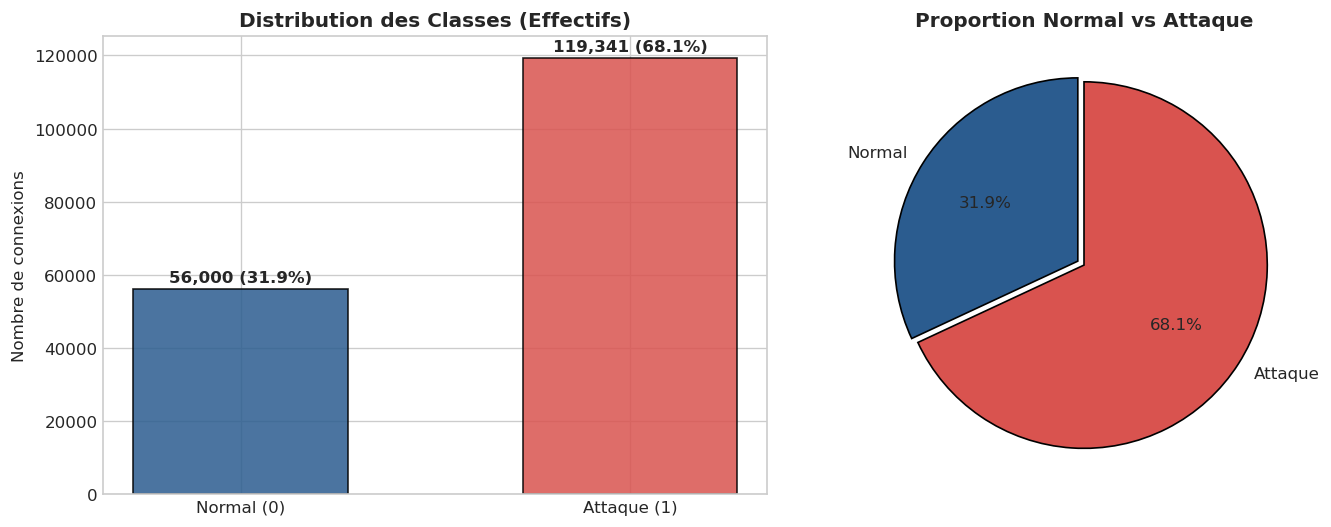

In [4]:
counts = df['label'].value_counts()
percents = (df['label'].value_counts(normalize=True) * 100).round(2)

class_dist = pd.DataFrame({
    'Classe': ['Normal (0)', 'Attaque (1)'],
    'Effectif': [counts[0], counts[1]],
    'Proportion (%)': [percents[0], percents[1]]
})
display(class_dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

colors = ['#2b5c8f', '#d9534f']
axes[0].bar(['Normal (0)', 'Attaque (1)'], [counts[0], counts[1]], color=colors, width=0.55, edgecolor='black', alpha=0.85)
axes[0].set_title("Distribution des Classes (Effectifs)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Nombre de connexions")
for i, v in enumerate([counts[0], counts[1]]):
    axes[0].text(i, v + 2000, f"{v:,} ({percents[i]:.1f}%)", ha='center', fontweight='bold')

axes[1].pie([counts[0], counts[1]], labels=['Normal', 'Attaque'], autopct='%1.1f%%',
            startangle=90, colors=colors, explode=(0.04, 0), wedgeprops={'edgecolor': 'black'})
axes[1].set_title("Proportion Normal vs Attaque", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Distribution Détaillée des Familles d'Attaques (`attack_cat`)

UNSW-NB15 regroupe 9 familles d'attaques modernes : Fuzzers, Analysis, Backdoors, DoS, Exploits, Generic, Reconnaissance, Shellcode, Worms.

,Catégorie,Effectif,Part des attaques (%)
0,Generic,40000,33.52
1,Exploits,33393,27.98
2,Fuzzers,18184,15.24
3,DoS,12264,10.28
4,Reconnaissance,10491,8.79
5,Analysis,2000,1.68
6,Backdoor,1746,1.46
7,Shellcode,1133,0.95
8,Worms,130,0.11
9,Normal,0,0.00


C:\Users\sami-gh\AppData\Local\Temp\ipykernel_30664\133245022.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=attack_counts.values, y=attack_counts.index, palette='viridis', edgecolor='black', alpha=0.9)


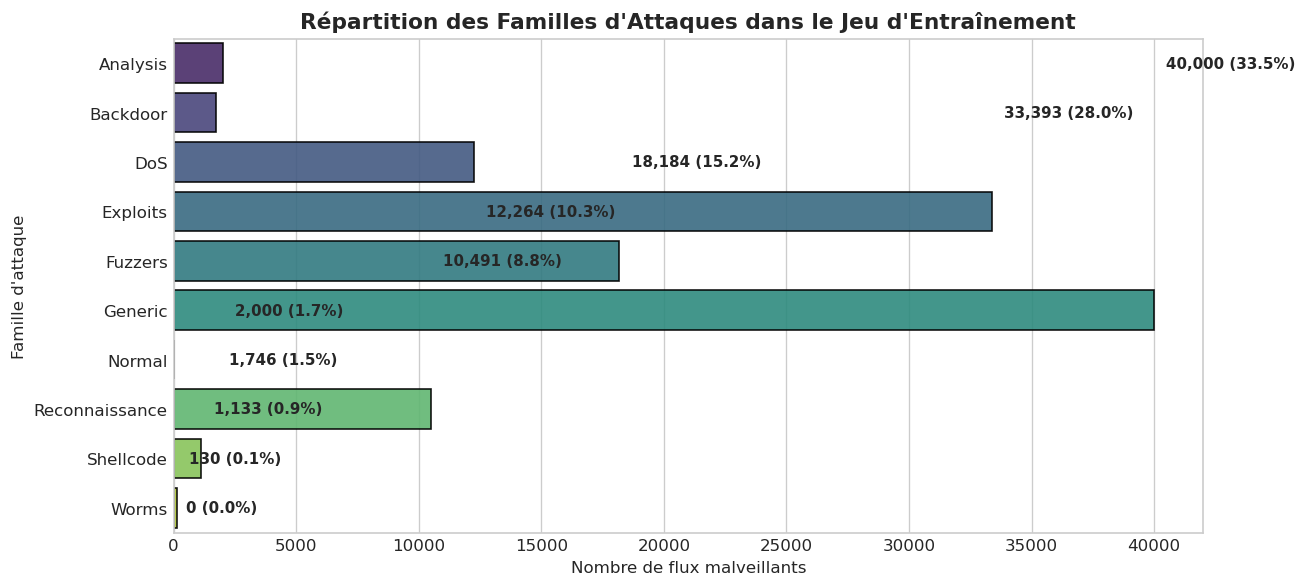

In [5]:
if 'attack_cat' in df.columns:
    attack_counts = df[df['label'] == 1]['attack_cat'].value_counts()
    attack_pcts = (df[df['label'] == 1]['attack_cat'].value_counts(normalize=True) * 100).round(2)

    attack_summary = pd.DataFrame({
        'Catégorie': attack_counts.index,
        'Effectif': attack_counts.values,
        'Part des attaques (%)': attack_pcts.values
    })
    display(attack_summary)

    plt.figure(figsize=(11, 5))
    sns.barplot(x=attack_counts.values, y=attack_counts.index, palette='viridis', edgecolor='black', alpha=0.9)
    plt.title("Répartition des Familles d'Attaques dans le Jeu d'Entraînement", fontsize=13, fontweight='bold')
    plt.xlabel("Nombre de flux malveillants")
    plt.ylabel("Famille d'attaque")
    for i, v in enumerate(attack_counts.values):
        plt.text(v + 500, i, f"{v:,} ({attack_pcts.iloc[i]:.1f}%)", va='center', fontsize=9, fontweight='bold')
    plt.tight_layout()
    plt.show()

## 6. Analyse des Protocoles et Services Réseau

C:\Users\sami-gh\AppData\Local\Temp\ipykernel_30664\733149349.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], x=top_proto.values, y=top_proto.index, palette='Blues_r', edgecolor='black')


C:\Users\sami-gh\AppData\Local\Temp\ipykernel_30664\733149349.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], x=top_service.values, y=top_service.index, palette='Greens_r', edgecolor='black')


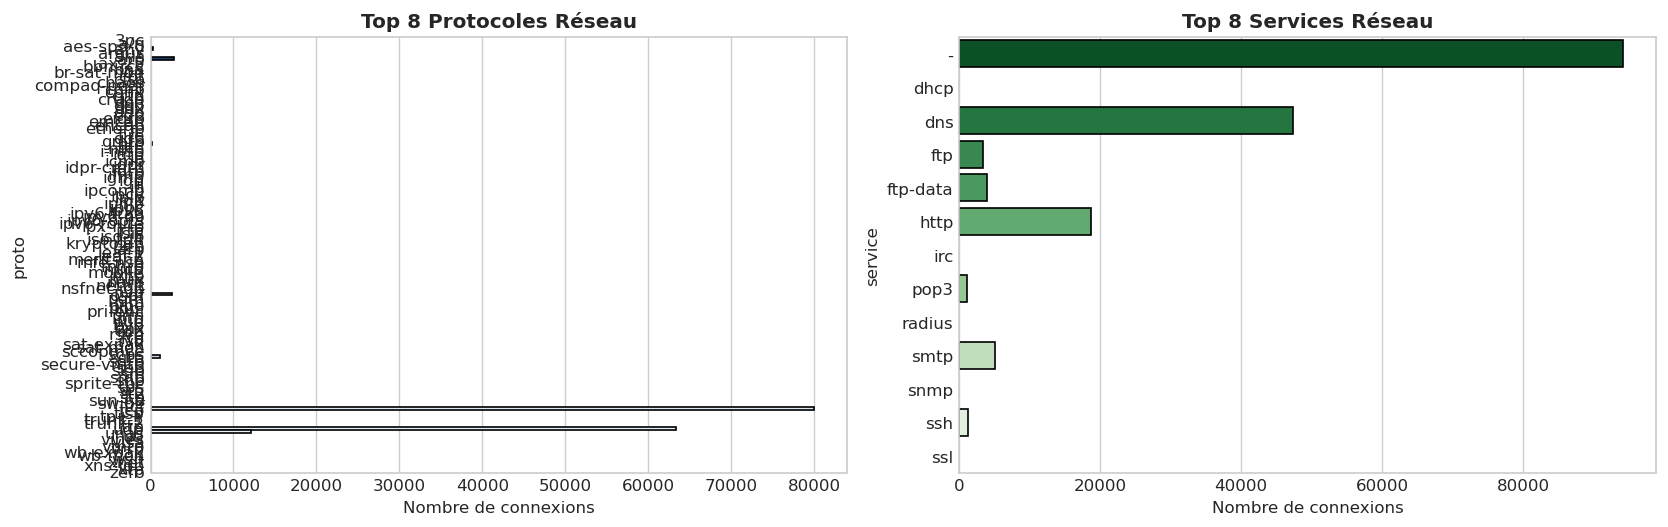

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

top_proto = df['proto'].value_counts().head(8)
sns.barplot(ax=axes[0], x=top_proto.values, y=top_proto.index, palette='Blues_r', edgecolor='black')
axes[0].set_title("Top 8 Protocoles Réseau", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Nombre de connexions")

top_service = df['service'].value_counts().head(8)
sns.barplot(ax=axes[1], x=top_service.values, y=top_service.index, palette='Greens_r', edgecolor='black')
axes[1].set_title("Top 8 Services Réseau", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Nombre de connexions")

plt.tight_layout()
plt.show()

## 7. Audit de la Qualité et Intégrité des Données

Contrôle rigoureux de :
1. **Valeurs manquantes (`NaN`)**
2. **Valeurs infinies (`+inf`, `-inf`)**
3. **Doublons exacts**

In [7]:
missing_total = df.isnull().sum().sum()
inf_total = np.isinf(df[num_cols]).sum().sum()
duplicates_total = df.duplicated().sum()

quality_report = pd.DataFrame({
    'Anomalie contrôlée': ['Valeurs manquantes (NaN)', 'Valeurs infinies (inf / -inf)', 'Lignes dupliquées exactes'],
    'Nombre détecté': [missing_total, inf_total, duplicates_total],
    'Statut': [
        '✔ Intègre (0 NaN)' if missing_total == 0 else f'⚠️ {missing_total} NaN détectées',
        '✔ Intègre (0 inf)' if inf_total == 0 else f'⚠️ {inf_total} inf détectées',
        f'⚠️ {duplicates_total:,} doublons à éliminer' if duplicates_total > 0 else '✔ Aucun doublon'
    ]
})
display(quality_report)

,Anomalie contrôlée,Nombre détecté,Statut
0,Valeurs manquantes (NaN),0,✔ Intègre (0 NaN)
1,Valeurs infinies (inf / -inf),0,✔ Intègre (0 inf)
2,Lignes dupliquées exactes,78519,"⚠️ 78,519 doublons à éliminer"


## 8. Nettoyage & Élimination des Fuites de Données (*Data Leakage*)

### Risque Majeur :
- La colonne `attack_cat` est une étiquette multi-classes qui révèle directement si le flux est une attaque (`label=1`). Elle doit être **strictement retirée** pour la classification binaire.
- La colonne `id` est un identifiant séquentiel de trace qui n'a aucune réalité physique dans un paquet réseau.
- Les **82 984 flux dupliqués** faussent la validation croisée en faisant apparaître les mêmes signatures dans les plis d'entraînement et de validation.

In [8]:
# 1. Suppression des colonnes sources de fuite
cols_to_drop = [c for c in ['id', 'attack_cat'] if c in df.columns]
df_clean = df.drop(columns=cols_to_drop)

# 2. Gestion des éventuelles valeurs infinies
num_cols_clean = df_clean.select_dtypes(include=[np.number]).columns
df_clean[num_cols_clean] = df_clean[num_cols_clean].replace([np.inf, -np.inf], np.nan)

# 3. Dédoublonnage
initial_count = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
final_count = len(df_clean)
dropped_duplicates = initial_count - final_count

print(f"Colonnes supprimées : {cols_to_drop}")
print(f"Doublons supprimés : {dropped_duplicates:,} flux ({dropped_duplicates / initial_count * 100:.1f}%)")
print(f"Nombre de flux uniques finaux : {final_count:,}")

Colonnes supprimées : ['attack_cat']
Doublons supprimés : 82,984 flux (47.3%)
Nombre de flux uniques finaux : 92,357


## 9. Nouvelle Distribution Après Nettoyage & Matrice de Corrélation

Distribution après nettoyage :
 - Trafic Normal (0) : 48,894 (52.94%)
 - Attaques (1)      : 43,463 (47.06%)


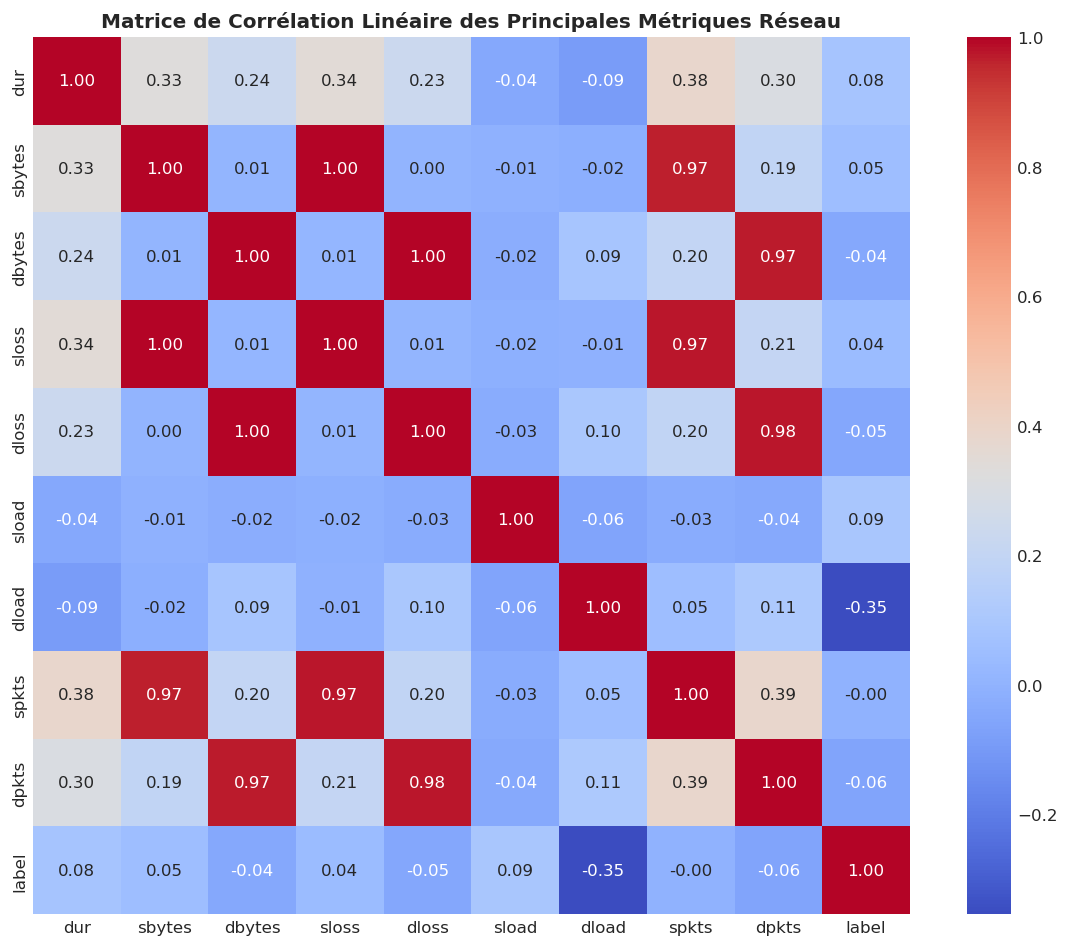

In [9]:
counts_clean = df_clean['label'].value_counts()
pcts_clean = (df_clean['label'].value_counts(normalize=True) * 100).round(2)

print(f"Distribution après nettoyage :")
print(f" - Trafic Normal (0) : {counts_clean[0]:,} ({pcts_clean[0]}%)")
print(f" - Attaques (1)      : {counts_clean[1]:,} ({pcts_clean[1]}%)")

# Analyse de corrélation sur les variables numériques clés
key_num_cols = ['dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'sload', 'dload', 'spkts', 'dpkts', 'label']
existing_keys = [c for c in key_num_cols if c in df_clean.columns]

plt.figure(figsize=(10, 8))
corr_matrix = df_clean[existing_keys].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title("Matrice de Corrélation Linéaire des Principales Métriques Réseau", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 10. Sauvegarde du Dataset Nettoyé

Le dataset nettoyé sans doublons et sans fuites d'information est sauvegardé au format binaire Parquet optimisé sous `data/UNSW_NB15_train_clean.parquet` pour l'étape de modélisation (Notebook 02).

In [10]:
output_clean_path = "../data/UNSW_NB15_train_clean.parquet"
df_clean.to_parquet(output_clean_path, index=False)
print(f"✔ Dataset nettoyé sauvegardé avec succès dans '{output_clean_path}'.")
print(f"  Fichier prêt pour le Notebook 02 (Modélisation, Optimisation & Évaluation).")

✔ Dataset nettoyé sauvegardé avec succès dans '../data/UNSW_NB15_train_clean.parquet'.
  Fichier prêt pour le Notebook 02 (Modélisation, Optimisation & Évaluation).
